In [87]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import ListedColormap
from scipy.stats import ks_2samp, anderson_ksamp

import warnings
import tqdm

## Reading samples

### HARPS

In [88]:
harps_c = pd.read_csv('harps_gaia_c.csv')
harps_mg_si = pd.read_csv('harps_gaia_mg_si.csv')
harps_o = pd.read_csv('harps_gaia_o.csv')

print (f'harps_c contains {len(harps_c)} stars')
print (f'harps_mg_si contains {len(harps_mg_si)} stars')    
print (f'harps_o contains {len(harps_o)} stars')

# Ensure 'source_id' is int and set as index
for df in [harps_mg_si, harps_c, harps_o]:
    df['source_id'] = df['source_id'].astype(int)
    df.set_index('source_id', inplace=True)

# Start with the base DataFrame
harps_combined = harps_mg_si.copy()

# Add only new columns from harps_c
new_cols_c = harps_c.columns.difference(harps_combined.columns)
harps_combined = harps_combined.join(harps_c[new_cols_c], how='left')

# Add only new columns from harps_o
new_cols_o = harps_o.columns.difference(harps_combined.columns)
harps_combined = harps_combined.join(harps_o[new_cols_o], how='left')

# Bring source_id back as a column
harps_combined.reset_index(inplace=True)

harps_combined.head(2)

harps_c contains 627 stars
harps_mg_si contains 798 stars
harps_o contains 232 stars


,source_id,Star,ra,dec,parallax,parallax_error,pmra,pmra_error,pmdec,pmdec_error,...,fe_h,e_fe_h,mg_h,e_mg_h,si_h,e_si_h,c_h,e_c_h,e_o_h,o_h
0,3790755044736796544,BD-012505,169.304406,-1.981918,30.138378,0.023513,-568.299830,0.017789,-14.309893,0.014746,...,-0.07,0.02,-0.13,0.10,0.09,0.09,NaN,NaN,NaN,NaN
1,4706630501049679744,HD55,1.322329,-67.835081,61.006400,0.019343,-116.617908,0.019904,-560.587881,0.018929,...,-0.67,0.01,-0.55,0.07,-0.46,0.08,NaN,NaN,NaN,NaN


### APOGEE

In [89]:
apogee = pd.read_csv('apogeeDR17_MST_final_sample.csv')

# Mapping from apogee column names to harps column names
apogee_rename_map = {
    'RA': 'ra',
    'DEC': 'dec',
    'GAIAEDR3_SOURCE_ID': 'source_id',
    'GAIAEDR3_PARALLAX': 'parallax',
    'GAIAEDR3_PARALLAX_ERROR': 'parallax_error',
    'GAIAEDR3_PMRA': 'pmra',
    'GAIAEDR3_PMRA_ERROR': 'pmra_error',
    'GAIAEDR3_PMDEC': 'pmdec',
    'GAIAEDR3_PMDEC_ERROR': 'pmdec_error',
    'GAIAEDR3_PHOT_G_MEAN_MAG': 'phot_g_mean_mag',
    'GAIAEDR3_PHOT_BP_MEAN_MAG': 'phot_bp_mean_mag',
    'GAIAEDR3_PHOT_RP_MEAN_MAG': 'phot_rp_mean_mag',
    'GAIAEDR3_R_MED_PHOTOGEO': 'distance_gspphot',  # best proxy
    'TEFF': 'Teff',
    'TEFF_ERR': 'e_Teff',
    'LOGG': 'logg',
    'LOGG_ERR': 'e_logg',
    'CI_H': 'c_h',
    'CI_H_ERR': 'e_c_h',
    'O_H': 'o_h',
    'O_H_ERR': 'e_o_h',
    'MG_H': 'mg_h',
    'MG_H_ERR': 'e_mg_h',
    'SI_H': 'si_h',
    'SI_H_ERR': 'e_si_h',
    'FE_H': 'fe_h',
    'FE_H_ERR': 'e_fe_h',
    'VHELIO_AVG': 'radial_velocity',
    'VERR': 'radial_velocity_error',
    'U_lsr': 'U_lsr',
    'V_lsr': 'V_lsr',
    'W_lsr': 'W_lsr',
    'P_gal': 'P_gal'
}

# Rename apogee columns
apogee_renamed = apogee.rename(columns=apogee_rename_map)
apogee_renamed.drop(['Unnamed: 0'], axis = 1, inplace = True)
apogee_renamed.head(2)

,ra,dec,GLON,GLAT,radial_velocity,radial_velocity_error,source_id,parallax,parallax_error,pmra,...,mg_h,e_mg_h,si_h,e_si_h,fe_h,e_fe_h,U_lsr,V_lsr,W_lsr,P_gal
0,0.005558,57.354549,116.014776,-4.824917,-101.71,0.07,421086363305436800,0.13,0.03,-1.15,...,-0.38,0.02,-0.42,0.03,-0.51,0.01,-89.86,-60.07,37.45,19.2
1,0.008802,63.463078,117.227985,1.162167,-106.63,0.03,431594980053422720,0.07,0.04,-0.92,...,-0.06,0.01,-0.09,0.02,-0.08,0.01,-125.17,-47.86,-43.08,5.1


### Galah

In [90]:
galah = pd.read_csv('galahDR4_final_sample.csv')
galah.drop(columns = ['Unnamed: 0', 'flag_c_fe'], axis = 1, inplace = True)
galah_c = pd.read_csv('galahDR4_final_carbon_sample.csv')

# Ensure both have the same type for the identifier
galah['gaiadr3_source_id'] = galah['gaiadr3_source_id'].astype(int)
galah_c['gaiadr3_source_id'] = galah_c['gaiadr3_source_id'].astype(int)

# Create a set of IDs from the cleaned DF
cleaned_ids = set(galah_c['gaiadr3_source_id'])

# Add the flag column to galah
galah['c_flag'] = galah['gaiadr3_source_id'].isin(cleaned_ids)

# Mapping from galah column names to harps-style column names
galah_rename_map = {
    'gaiadr3_source_id': 'source_id',
    'rv_comp_1': 'radial_velocity',
    'e_rv_comp_1': 'radial_velocity_error',
    'teff': 'Teff',
    'e_teff': 'e_Teff',
    'logg': 'logg',
    'e_logg': 'e_logg',
    'fe_h': 'fe_h',
    'e_fe_h': 'e_fe_h',
    'c_h': 'c_h',
    'e_c_h': 'e_c_h',
    'o_h': 'o_h',
    'e_o_h': 'e_o_h',
    'mg_h': 'mg_h',
    'e_mg_h': 'e_mg_h',
    'si_h': 'si_h',
    'e_si_h': 'e_si_h',
    'ra': 'ra',
    'dec': 'dec',
    'parallax': 'parallax',
    'parallax_error': 'parallax_error',
    'pmra': 'pmra',
    'pmra_error': 'pmra_error',
    'pmdec': 'pmdec',
    'pmdec_error': 'pmdec_error',
    'phot_g_mean_mag': 'phot_g_mean_mag',
    'phot_bp_mean_mag': 'phot_bp_mean_mag',
    'phot_rp_mean_mag': 'phot_rp_mean_mag',
    'r_med_photogeo': 'distance_gspphot',  # rename to harps-style
    'U_lsr': 'U_lsr',
    'V_lsr': 'V_lsr',
    'W_lsr': 'W_lsr',
    'P_gal': 'P_gal'
}

# Apply the renaming
galah_renamed = galah.rename(columns=galah_rename_map)

In [91]:
def compare_dfs_by_source_id(df1, df2, label1='df1', label2='df2', id_col='source_id'):
    """
    Crossmatches two DataFrames by source_id and compares common numeric columns.
    
    Parameters:
        df1, df2: pandas DataFrames
        label1, label2: labels used for suffixes and reporting
        id_col: column to match on (default: 'source_id')
    
    Returns:
        merged_df: merged DataFrame with suffixes
        comparison_df: DataFrame with mean and max absolute differences per column
    """
    # Ensure ID column is string to avoid mismatches
    df1 = df1.copy()
    df2 = df2.copy()
    df1[id_col] = df1[id_col].astype(int)
    df2[id_col] = df2[id_col].astype(int)
    
    # Merge
    merged_df = pd.merge(df1, df2, on=id_col, suffixes=(f'_{label1}', f'_{label2}'))
    print(f"Matched rows: {len(merged_df)} / {len(df1)} {label1.upper()} entries")
    
    # Get common columns
    common_cols = list(set(df1.columns) & set(df2.columns))
    
    # Compare only numeric columns
    comparison_stats = []
    for col in common_cols:
        col_1 = f"{col}_{label1}"
        col_2 = f"{col}_{label2}"
        if col_1 in merged_df.columns and col_2 in merged_df.columns:
            try:
                # Convert to numeric
                series_1 = pd.to_numeric(merged_df[col_1], errors='coerce')
                series_2 = pd.to_numeric(merged_df[col_2], errors='coerce')
                diff = (series_1 - series_2).abs()
                comparison_stats.append({
                    'column': col,
                    'mean_abs_diff': diff.mean(),
                    'max_abs_diff': diff.max(),
                    'n_nan': diff.isna().sum()
                })
            except Exception:
                continue

    comparison_df = pd.DataFrame(comparison_stats)
    comparison_df.sort_values(by='mean_abs_diff', ascending=False, inplace=True)
    
    return merged_df, comparison_df


In [92]:
merged_harps_apogee, comp_harps_apogee = compare_dfs_by_source_id(harps_combined, apogee_renamed, label1='harps', label2='apogee')
merged_harps_galah, comp_harps_galah  = compare_dfs_by_source_id(harps_combined, galah_renamed, label1='harps', label2='galah')
merged_galah_apogee, comp_galah_apogee = compare_dfs_by_source_id(galah_renamed, apogee_renamed, label1='galah', label2='apogee')

Matched rows: 4 / 798 HARPS entries
Matched rows: 6 / 798 HARPS entries
Matched rows: 886 / 116050 GALAH entries


In [93]:
other_cols = ['distance_gspphot',  'Teff',   'dec',  'phot_rp_mean_mag',  'parallax',  'pmra',  'pmdec',  
              'phot_bp_mean_mag',  'ra',  'logg',  'phot_g_mean_mag', ]


cols_for_ml = ['radial_velocity',  'V_lsr',  'U_lsr',  'W_lsr', 'P_gal', 
            'o_h', 'c_h',  'fe_h', 'mg_h',  'si_h']

In [94]:
def distribution_test_trio(df1, df2, df3, features, labels=("df1", "df2", "df3")):
    """
    Compare distributions using KS and AD tests across three datasets.

    Parameters:
        df1, df2, df3: DataFrames to compare
        features: list of feature names to test
        labels: tuple of labels for the dataframes (used in column names)

    Returns:
        pandas DataFrame with KS and AD p-values for each feature and pair
    """
    results = []

    for feature in features:
        try:
            # Extract valid (non-NaN) numeric values
            x1 = pd.to_numeric(df1[feature], errors='coerce').dropna()
            x2 = pd.to_numeric(df2[feature], errors='coerce').dropna()
            x3 = pd.to_numeric(df3[feature], errors='coerce').dropna()

            # Apply tests if all groups have data
            if len(x1) >= 10 and len(x2) >= 10:
                ks_12 = ks_2samp(x1, x2).pvalue
                try:
                    ad_12 = anderson_ksamp([x1, x2]).pvalue
                except Exception:
                    ad_12 = np.nan
            else:
                ks_12 = ad_12 = np.nan

            if len(x1) >= 10 and len(x3) >= 10:
                ks_13 = ks_2samp(x1, x3).pvalue
                try:
                    ad_13 = anderson_ksamp([x1, x3]).pvalue
                except Exception:
                    ad_13 = np.nan
            else:
                ks_13 = ad_13 = np.nan

            if len(x2) >= 10 and len(x3) >= 10:
                ks_23 = ks_2samp(x2, x3).pvalue
                try:
                    ad_23 = anderson_ksamp([x2, x3]).pvalue
                except Exception:
                    ad_23 = np.nan
            else:
                ks_23 = ad_23 = np.nan

            results.append({
                'feature': feature,
                f'KS_{labels[0]}_{labels[1]}': ks_12,
                #f'AD_{labels[0]}_{labels[1]}': ad_12,
                f'KS_{labels[0]}_{labels[2]}': ks_13,
                #f'AD_{labels[0]}_{labels[2]}': ad_13,
                f'KS_{labels[1]}_{labels[2]}': ks_23,
                #f'AD_{labels[1]}_{labels[2]}': ad_23,
            })

        except Exception as e:
            print(f"Error processing {feature}: {e}")
            continue

    df = pd.DataFrame(results)
    for col in df.columns:
        if col != 'feature' and df[col].dtype == float:
            df[col] = df[col].map(lambda x: f"{x:.3f}" if pd.notna(x) else "")
    return df


In [95]:
features_to_test = cols_for_ml  # or your ML feature list
results_df = distribution_test_trio(harps_combined, apogee_renamed, galah_renamed, features_to_test, labels=('HARPS', 'APOGEE', 'GALAH'))
results_df


/tmp/ipykernel_37400/3184350185.py:26: UserWarning: p-value floored: true value smaller than 0.001. Consider specifying `method` (e.g. `method=stats.PermutationMethod()`.)
  ad_12 = anderson_ksamp([x1, x2]).pvalue
/tmp/ipykernel_37400/3184350185.py:44: UserWarning: p-value floored: true value smaller than 0.001. Consider specifying `method` (e.g. `method=stats.PermutationMethod()`.)
  ad_23 = anderson_ksamp([x2, x3]).pvalue
/tmp/ipykernel_37400/3184350185.py:35: UserWarning: p-value floored: true value smaller than 0.001. Consider specifying `method` (e.g. `method=stats.PermutationMethod()`.)
  ad_13 = anderson_ksamp([x1, x3]).pvalue


,feature,KS_HARPS_APOGEE,KS_HARPS_GALAH,KS_APOGEE_GALAH
0,radial_velocity,0.000,0.048,0.000
1,V_lsr,0.000,0.114,0.000
2,U_lsr,0.000,0.000,0.000
3,W_lsr,0.000,0.140,0.000
4,P_gal,0.000,0.001,0.000
5,o_h,0.000,0.196,0.000
6,c_h,0.000,0.062,0.000
7,fe_h,0.000,0.079,0.000
8,mg_h,0.004,0.000,0.000
9,si_h,0.000,0.000,0.000


In [96]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
import warnings

color_list = ["#1f77b4",  # blue
              "#ff7f0e",  # orange
              "#2ca02c"]  # green

cmap_custom = ListedColormap(color_list)

def plot_distribution_trio(df1, df2, df3, feature, labels=("df1", "df2", "df3"), hue="set", palette=color_list):
    # Add source labels
    df1_copy = df1.copy()
    df1_copy[hue] = labels[0]
    df2_copy = df2.copy()
    df2_copy[hue] = labels[1]
    df3_copy = df3.copy()
    df3_copy[hue] = labels[2]

    # Concatenate all
    data_df = pd.concat([df1_copy, df2_copy, df3_copy], ignore_index=True)

    # Replace infs and drop non-numeric/missing
    data_df.replace([np.inf, -np.inf], np.nan, inplace=True)
    data_df = data_df[pd.to_numeric(data_df[feature], errors='coerce').notna()]
    data_df[feature] = data_df[feature].astype(float)

    # Begin plotting
    f, axes = plt.subplots(1, 2, figsize=(16, 6))

    # Histogram
    for i, s in enumerate(data_df[hue].unique()):
        selection = data_df.loc[data_df[hue] == s, feature]
        if len(selection) < 10:
            continue

        q_025, q_975 = np.percentile(selection, [2.5, 97.5])
        selection_filtered = selection[(selection >= q_025) & (selection <= q_975)]

        with warnings.catch_warnings():
            warnings.simplefilter("ignore", category=FutureWarning)
            sns.histplot(selection_filtered, color=palette[i], ax=axes[0], label=s, kde=False)

    # Boxplot
    sns.boxplot(x=hue, y=feature, data=data_df, palette=palette, ax=axes[1])

    # Titles and legends
    axes[0].set_title(f"[2.5%-97.5%] Distribution of {feature}")
    axes[1].set_title(f"Boxplot of {feature}")
    axes[0].legend()
    plt.tight_layout()
    plt.show()


/tmp/ipykernel_37400/958559016.py:48: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x=hue, y=feature, data=data_df, palette=palette, ax=axes[1])


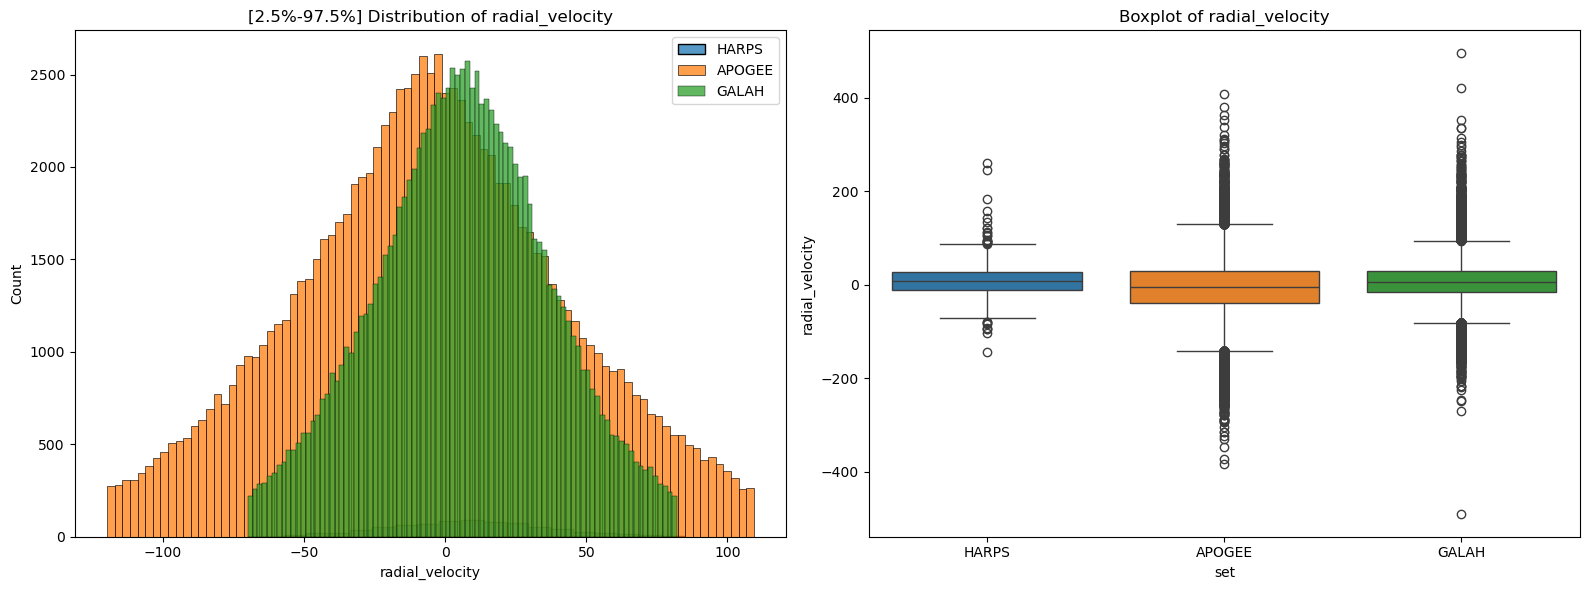

In [97]:
#for feature in cols_for_ml:
#    print(feature)
#    plot_distribution_trio(harps_combined, apogee_renamed, galah_renamed, feature=feature, labels=("HARPS", "APOGEE", "GALAH"))

# Use appropriate renamings if not done already
plot_distribution_trio(harps_combined, apogee_renamed, galah_renamed, feature='radial_velocity', labels=("HARPS", "APOGEE", "GALAH"))


In [98]:
def plot_element_minus_feh_vs_feh(dfs, element='mg_h', labels=None, colors=None):
    """
    Plots [X/H] - [Fe/H] vs [Fe/H] for 2 or 3 DataFrames, with mean [X/Fe] in [-0.1, 0.1] annotated.

    Parameters:
        dfs: list of 2 or 3 pandas DataFrames
        element: string, element column name (e.g., 'mg_h')
        labels: list of labels (same length as dfs)
        colors: list of colors (same length as dfs)
    """
    if not (2 <= len(dfs) <= 3):
        raise ValueError("Please provide 2 or 3 DataFrames.")

    if labels is None:
        labels = [f'DF{i+1}' for i in range(len(dfs))]
    if len(labels) != len(dfs):
        raise ValueError("Length of 'labels' must match number of DataFrames.")

    if colors is None:
        default_colors = ["#1f77b4", "#ff7f0e", "#2ca02c"]
        colors = default_colors[:len(dfs)]

    fig, ax = plt.subplots(figsize=(10, 6))
    label_elem = element.split("_")[0].capitalize()
    y_offset = 0.05

    for i, (df, label, color) in enumerate(zip(dfs, labels, colors)):
        try:
            x = pd.to_numeric(df['fe_h'], errors='coerce')
            y = pd.to_numeric(df[element], errors='coerce')
            mask = x.notna() & y.notna()
            x = x[mask]
            y = y[mask]
            delta = y - x

            ax.scatter(x, delta, alpha=0.5, label=label, s=20, color=color)

            sel_mask = (x >= -0.1) & (x <= 0.1)
            if sel_mask.sum() >= 5:
                mean_val = delta[sel_mask].mean()
                ax.annotate(
                    f"{label}: {mean_val:.3f}",
                    xy=(0.05, 0.05 + i * y_offset),
                    xycoords='data',
                    color=color,
                    fontsize=10,
                    ha='left',
                    va='center',
                    bbox=dict(boxstyle="round,pad=0.3", fc="white", ec=color, lw=1)
                )
        except Exception as e:
            print(f"Skipping {label} due to error: {e}")

    ax.axhline(0, color='gray', linestyle='--', lw=1)
    ax.set_xlabel('[Fe/H]')
    ax.set_ylabel(f'[{label_elem}/Fe]')
    ax.set_title(f'[{label_elem}/Fe] vs [Fe/H]')
    ax.legend()
    ax.grid(True)
    plt.tight_layout()
    plt.show()


In [99]:
apogee_renamed

,ra,dec,GLON,GLAT,radial_velocity,radial_velocity_error,source_id,parallax,parallax_error,pmra,...,mg_h,e_mg_h,si_h,e_si_h,fe_h,e_fe_h,U_lsr,V_lsr,W_lsr,P_gal
0,0.005558,57.354549,116.014776,-4.824917,-101.71,0.07,421086363305436800,0.13,0.03,-1.15,...,-0.38,0.02,-0.42,0.03,-0.51,0.01,-89.86,-60.07,37.45,19.2
1,0.008802,63.463078,117.227985,1.162167,-106.63,0.03,431594980053422720,0.07,0.04,-0.92,...,-0.06,0.01,-0.09,0.02,-0.08,0.01,-125.17,-47.86,-43.08,5.1
2,0.009748,14.875667,104.845530,-46.183158,-38.50,0.03,2771993642553377280,4.57,0.21,-28.31,...,0.36,0.01,0.35,0.01,0.32,0.00,-72.97,-39.00,-2.14,93.1
3,0.018603,58.909149,116.330761,-3.302585,-48.05,0.03,422775384964691328,0.22,0.02,-2.24,...,-0.08,0.02,-0.07,0.02,-0.08,0.01,-80.61,-7.89,-5.64,96.4
4,0.022759,61.869644,116.918992,-0.401038,-33.46,0.02,429530195985183744,0.37,0.02,2.00,...,-0.20,0.01,-0.26,0.02,-0.28,0.01,-0.49,-30.58,19.57,97.3
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
108521,359.981260,64.049225,117.332266,1.739098,-127.72,0.03,2016199730570963968,0.20,0.03,-1.68,...,-0.18,0.01,-0.23,0.02,-0.27,0.01,-103.28,-84.19,14.10,8.2
108522,359.983620,62.853386,117.096010,0.566818,-58.58,0.02,2013020767578111360,0.25,0.01,-1.25,...,-0.02,0.01,-0.08,0.01,-0.10,0.01,-63.17,-26.68,-15.51,95.6
108523,359.986225,61.523659,116.833497,-0.736743,-24.95,0.03,2011912391134705920,0.29,0.01,0.01,...,-0.40,0.02,-0.37,0.02,-0.41,0.01,-22.28,-10.07,7.32,98.9
108524,359.986523,79.302002,120.457508,16.678604,-38.77,0.02,2282127264957087872,0.42,0.01,6.96,...,-0.21,0.02,-0.30,0.02,-0.50,0.01,41.18,-78.28,44.14,7.8


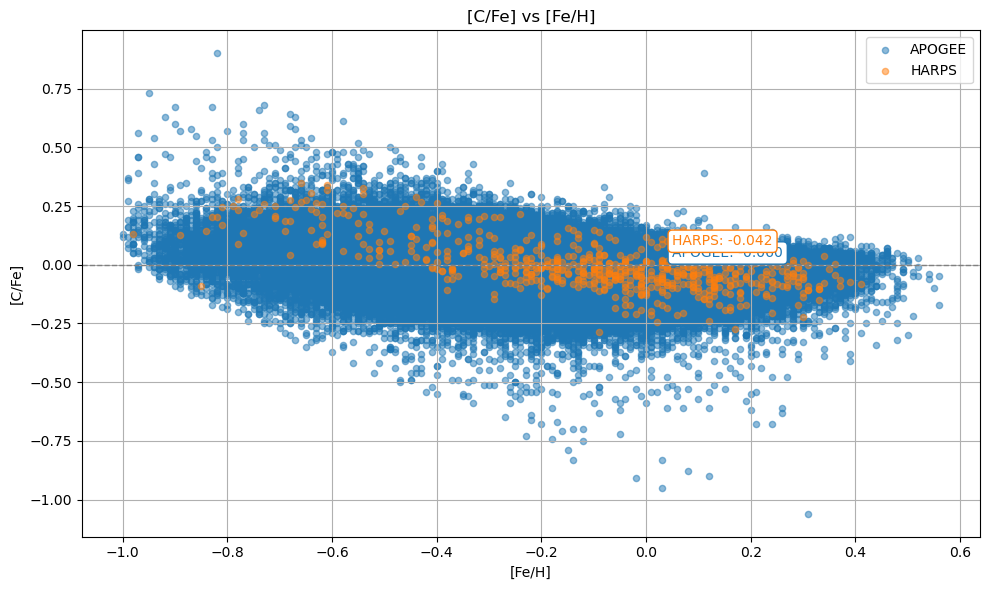

In [100]:
plot_element_minus_feh_vs_feh(
    dfs=[apogee_renamed, harps_combined,],
    element='c_h',
    labels=[ 'APOGEE', 'HARPS']
)
